# Parallel-in-time integration with MEP (mean-element parareal)

A long-term integration of a planetary system is inherently sequential: every time step starts from the exact result of the previous one, and one WHFast512 step of the Solar System takes only about 100 ns, far too little to split across cores. So far, additional cores could only be used to run *more* simulations, not to finish *one* simulation sooner.

**MEP** (mean-element parareal) changes that. It cuts the time axis into windows of `cores` slices and integrates all slices of a window at the same time with WHFast512, one thread per slice. A cheap coarse propagator, built from a perturbation theory in *mean* orbital elements, links the slices (the parareal algorithm). After a few iterations every window has converged to the serial WHFast512 trajectory within a tolerance `tol`. For the Solar System, a 5 Gyr integration takes about 3 hours on a 16-core workstation instead of 9 hours with serial WHFast512, at the accuracy of the serial integrator.

This tutorial shows how to
* run MEP from Python,
* **stop** a run (wall-clock limit or Ctrl-C) and **resume** it from a small checkpoint file, bitwise identically,
* check the result against a serial WHFast512 integration.

The whole notebook runs in about 20 seconds.

**Requirements.** Linux; a central object and **exactly eight planets** ordered by distance (the four inner planets are treated by perturbation theory in the coarse step, the four outer ones are integrated directly); the WHFast512 integrator; units with $G=1$. The method was designed and validated for the Solar System.

## Setting up the Solar System

We use the built-in Solar System initial conditions and the WHFast512 setup of the paper by Dagli & Rein (2026): a time step of 6 days, symplectic correctors of order 17, and the general relativistic correction.

In [1]:
import parachron
import numpy as np
import os, time

def solar_system():
    sim = parachron.Simulation()
    sim.add("solar system")            # built-in initial conditions (Sun + 8 planets)
    sim.integrator = "whfast512"
    sim.dt = 6.0/365.25*2.*np.pi       # 6 days (time unit: yr/2pi)
    sim.exact_finish_time = False
    sim.integrator.gr_potential = 1
    sim.integrator.corrector = 17
    return sim

sim = solar_system()

## A first MEP run

`parachron.MEP` takes the simulation and a few options. By default it uses all physical cores of the machine (`cores`), slices of 60000 steps (986 years at a 6-day step) and the reference tolerance `tol = 3e-6` AU. The optional `checkpoint` file receives the state of the run every `checkpoint_every` windows and at the end of every `integrate` call.

MEP always integrates whole windows of `cores` slices; `integrate(tmax)` stops at the last window boundary before `tmax`.

In [2]:
for f in ("run.mep", "run.mep.tmp"):
    if os.path.exists(f): os.remove(f)

mep = parachron.MEP(sim, checkpoint="run.mep", checkpoint_every=10)
print(f"{mep.cores} cores, one window = {mep.window_length/2/np.pi:.0f} years")

6 cores, one window = 5914 years


We want to integrate for 1.5 Myr, but pretend that our time allocation is short: `walltime=3` stops the integration after the first window that ends after 3 seconds of wall clock. The function returns `False` if it stopped early.

In [3]:
tmax = 1.5e6*2.*np.pi
finished = mep.integrate(tmax, walltime=3)
print("finished:", finished)
print(f"t = {mep.t/2/np.pi:.0f} yr after {mep.windows} windows, {mep.walltime_last:.1f} s")
print("iterations per window:", mep.iterations)

finished: False
t = 520411 yr after 88 windows, 3.0 s
iterations per window: {3: 86, 4: 2}


The simulation `sim` has been updated to the end of the last completed window, so it can be used for output and analysis as usual:

In [4]:
print(f"sim.t = {sim.t/2/np.pi:.0f} yr")
print(f"Mercury: a = {sim.particles[1].a:.6f} AU, e = {sim.particles[1].e:.6f}")

sim.t = 520411 yr
Mercury: a = 0.387098 AU, e = 0.144386


## Stopping and resuming

The checkpoint file is tiny: it holds the exact state (the planets' orbital elements), the time, the options and some statistics. It is written atomically (to a temporary file that is then renamed), so a crash never leaves a broken checkpoint behind.

In [5]:
print(f"checkpoint size: {os.path.getsize('run.mep')} bytes")

checkpoint size: 688 bytes


To show that a run can be continued later, even in a new Python process or on another day, we delete the MEP object and resume from the file. `MEP.from_checkpoint` restores everything that affects the result (number of cores per window, tolerance, time step, ...) from the file; the new object has its own `sim` with the checkpointed state.

In [6]:
del mep, sim

mep = parachron.MEP.from_checkpoint("run.mep")
print(f"resumed at t = {mep.t/2/np.pi:.0f} yr ({mep.windows} windows done)")
finished = mep.integrate(tmax)          # no wall-clock limit: run to the end
print("finished:", finished)
print(f"t = {mep.t/2/np.pi:.0f} yr after {mep.windows} windows; mean iterations per window {mep.mean_iterations:.2f}")

resumed at t = 520411 yr (88 windows done)


finished: True
t = 1496181 yr after 253 windows; mean iterations per window 3.05


**Interrupting.** You can also stop a run with Ctrl-C (or the stop button of the notebook). MEP then raises `KeyboardInterrupt`; the window that was being computed is discarded, and `mep.sim` and the checkpoint hold the last completed window. Resuming works exactly as above.

## Is the resumed run identical to an uninterrupted one?

We repeat the integration without interruption and, at the same time, record Mercury's eccentricity after every window. Integrating in several `integrate` calls does not change the result either, because every window starts only from the converged end state of the previous one.

In [7]:
ref = parachron.MEP(solar_system())           # same options, no checkpoint
times, ecc = [], []
while ref.t + ref.window_length <= tmax*(1+1e-12):
    ref.integrate(ref.t + ref.window_length)
    times.append(ref.t/2/np.pi)
    ecc.append(ref.sim.particles[1].e)
print(f"{ref.windows} windows")
print("bitwise identical to the stopped-and-resumed run:", ref.state == mep.state and ref.t == mep.t)

253 windows
bitwise identical to the stopped-and-resumed run: True


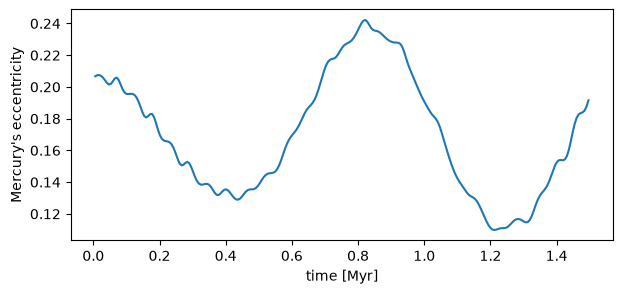

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.array(times)/1e6, ecc)
ax.set_xlabel("time [Myr]")
ax.set_ylabel("Mercury's eccentricity");

## Comparison with serial WHFast512

Finally, we integrate the first part of the run with ordinary serial WHFast512 and compare. The serial run uses the same synchronization as MEP (one call per slice, `jacobi_recursive = 1`). The planet positions agree to about $10^{-5}$ AU after some $10^5$ years. Differences of this size also arise between two serial runs that differ only in round-off (for example with two different WHFast512 kernels); in the chaotic Solar System they grow with time, but the dynamics remain statistically identical. The speed-up depends on the number of cores: about 1.5 on 6 cores and 3.1 on 16 cores.

In [9]:
nwin = 20
test = parachron.MEP(solar_system())
test.integrate(nwin*test.window_length)

ser = solar_system()
ser.integrator.jacobi_recursive = 1
ser.integrator.concatenate_steps = 60000     # one call per slice
t0 = time.time()
for _ in range(nwin*test.cores):
    ser.steps(1)
t_serial = time.time() - t0

d = max(np.linalg.norm(np.array(test.sim.particles[i].xyz) - np.array(ser.particles[i].xyz)) for i in range(1, 9))
print(f"time: {ser.t/2/np.pi:.0f} yr (MEP {test.t/2/np.pi:.0f} yr)")
print(f"serial {t_serial:.2f} s, MEP {test.walltime_last:.2f} s -> speed-up {t_serial/test.walltime_last:.2f} on {test.cores} cores")
print(f"largest planet position difference: {d:.1e} AU")

time: 118275 yr (MEP 118275 yr)
serial 1.00 s, MEP 0.73 s -> speed-up 1.36 on 6 cores
largest planet position difference: 7.7e-06 AU


## Options and tips

* `tol`: tolerance [AU] of the stopping rule. The default `3e-6` gives the accuracy of serial WHFast512 (secular frequencies within $10^{-7}$ "/yr of a serial run). `3e-5` is about 15% faster and was validated by ensembles of integrations.
* `cores`: one slice per core; use physical cores only. Threads are pinned to cores (`pin=True`); the helper threads of the coarse step run on the second hardware threads (SMT siblings).
* `checkpoint_every`: windows between checkpoints. The cost of a checkpoint is negligible.
* Only one MEP integration can run at a time in a process.
* From C, the same functionality is available through `reb_mep_create`, `reb_mep_create_from_checkpoint`, `reb_mep_integrate`, `reb_mep_update_simulation` and `reb_mep_free` (see `examples/mep_solar_system`).

In [10]:
for f in ("run.mep",):
    if os.path.exists(f): os.remove(f)